# Full-graph inductive YAGO results

Executed from committed experiment evidence; embedded PNG outputs render on GitHub.
No local graph, checkpoint or GPU is needed to rerun this notebook.

The encoder uses ID-independent directional relation-count features and a
`tf_gnns` MPNN, with a contextual ComplEx decoder. Shallow ID tables are trained
separately and are **not** inputs to the transferable encoder.

**Protocol:** sampled-filtered tail prediction, 2,000 queries per test cohort,
up to 50 negatives, pessimistic model ties. These are not full-ranking metrics.
Checkpoint selection uses only temporal validation (mean of uniform/range MRR).


In [1]:
import json
from pathlib import Path
from IPython.display import display, Markdown, Image

root = Path.cwd()
if not (root / 'experiments').exists():
    root = root.parent
report = root / 'experiments/inductive_full_entity2'
summary = json.loads((report / 'summary.json').read_text())
results = summary['results']

def table(headers, rows):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n|'
                     + '|'.join(['---'] * len(headers)) + '|\n'
                     + '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)))

table(['Dataset / budget', 'Value'], [
    ['Mapped entities', f"{summary['num_nodes']:,}"],
    ['Training facts', f"{summary['splits']['train']:,}"],
    ['Inference-support facts', f"{summary['splits']['support']:,}"],
    ['Relations', summary['num_relations']],
    ['Updates / selected step', f"{summary['completed_steps']:,} / {summary['best']['step']:,}"],
    ['Seed-draw-equivalent epochs', f"{summary['seed_draw_equivalent_epochs']:.6f}"],
])


| Dataset / budget | Value |
|---|---|
| Mapped entities | 49,281,921 |
| Training facts | 96,428,602 |
| Inference-support facts | 21,783,785 |
| Relations | 63 |
| Updates / selected step | 185,111 / 185,000 |
| Seed-draw-equivalent epochs | 0.901472 |

The uncapped archive yielded 119,045,262 structural entity–entity facts.
Temporal exclusion, deduplication and independent splits produce the counts above.
The full graph is available as context; supervised anchor draws cover every
training entity (see the draws/epochs row), which is participation coverage,
**not** an exhaustive supervised pass over every training fact.

## Unseen-entity link prediction and controls

In [2]:
rows = []
for policy in ['uniform', 'relation-range']:
    r = results['trained_' + policy]
    rows.append([policy, f"{r['mrr']:.6f}",
                 '–'.join(f'{v:.6f}' for v in r['mrr_ci95']),
                 f"{r['hits1']:.4f}", f"{r['hits10']:.4f}",
                 f"{r['frequency_mrr']:.6f}"])
table(['Candidates', 'GNN MRR', '95% bootstrap CI', 'Hits@1', 'Hits@10',
       'Frequency MRR (expected ties)'], rows)
gain = results['message_passing_gain']
display(Markdown(f"No-message range MRR: **{results['no_message_relation_range']['mrr']:.6f}**. "
                 f"Paired message-passing gain: **{gain['mean_delta_mrr']:.6f}**, "
                 f"95% CI {gain['paired_bootstrap_ci95']}."))

| Candidates | GNN MRR | 95% bootstrap CI | Hits@1 | Hits@10 | Frequency MRR (expected ties) |
|---|---|---|---|---|---|
| uniform | 0.974023 | 0.968300–0.979422 | 0.9605 | 0.9980 | 0.964812 |
| relation-range | 0.886853 | 0.876077–0.897792 | 0.8255 | 0.9845 | 0.779454 |

No-message range MRR: **0.675571**. Paired message-passing gain: **0.211282**, 95% CI [0.19509716011928582, 0.2266021702166175].

Frequency is a strong control: global negatives often make this task easy.
Full directional degree features encode powerful predicate-range information;
high sampled MRR alone is not evidence of general semantic reasoning.
The no-message ablation retains structural features but removes messages.
Raw rankings, relation groups and support-degree groups are retained in the report.
Degree-matched candidates are an additional diagnostic, not a tuning objective.

## Temporal test: valid-time completion

In [3]:
table(['Candidates', 'GNN MRR', 'Frequency MRR', 'Hits@1', 'Hits@10'], [
    [policy, f"{results['temporal_test_' + policy]['mrr']:.6f}",
     f"{results['temporal_test_' + policy]['frequency_mrr']:.6f}",
     f"{results['temporal_test_' + policy]['hits1']:.4f}",
     f"{results['temporal_test_' + policy]['hits10']:.4f}"]
    for policy in ['uniform', 'relation-range']])

| Candidates | GNN MRR | Frequency MRR | Hits@1 | Hits@10 |
|---|---|---|---|---|
| uniform | 0.859868 | 0.838928 | 0.7860 | 0.9880 |
| relation-range | 0.582621 | 0.387878 | 0.4555 | 0.8385 |

Dates are earliest triple-level validity starts: training through 2010,
validation 2011–2018, test 2019–2024. Undated static background remains available.
**This is not causal knowledge-acquisition forecasting.** Neither test policy
was used for checkpoint selection or further tuning; compare each GNN number
against its own frequency control in the table above.

## Losses and validation curves

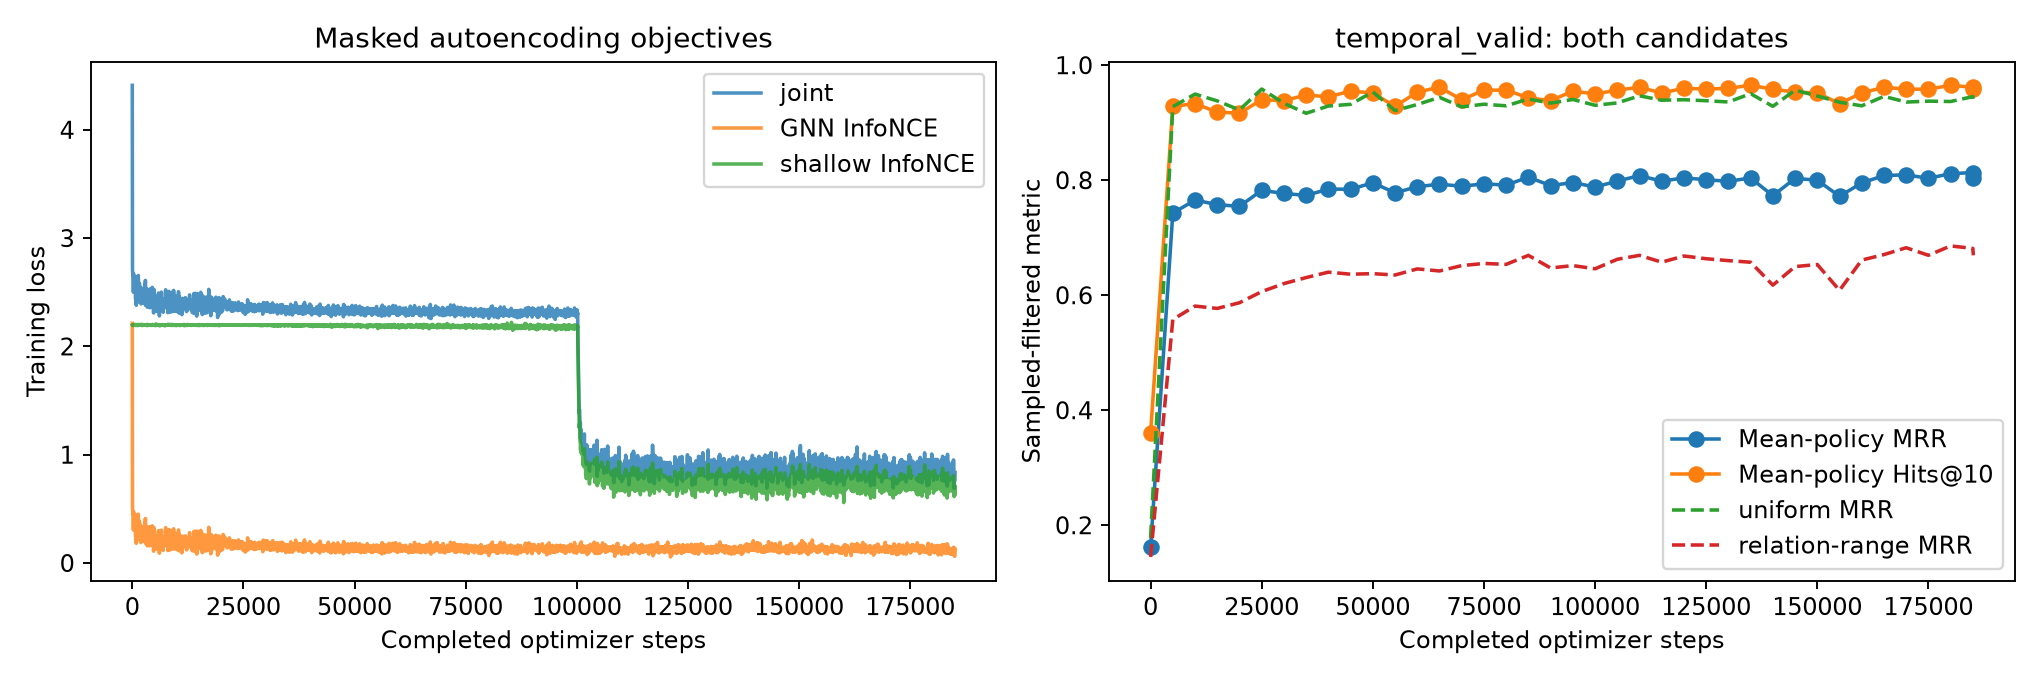

| Final objective | Loss |
|---|---|
| GNN | 0.129808 |
| Shallow | 0.705525 |
| Joint | 0.835333 |

In [4]:
display(Image(filename=str(report / 'learning_curves.png')))
table(['Final objective', 'Loss'], [
    [name, f"{summary['training_final'][key]:.6f}"]
    for name, key in [('GNN', 'gnn_loss'), ('Shallow', 'shallow_loss'), ('Joint', 'loss')]])

## Contextual GNN t-SNE — actual full-run vectors

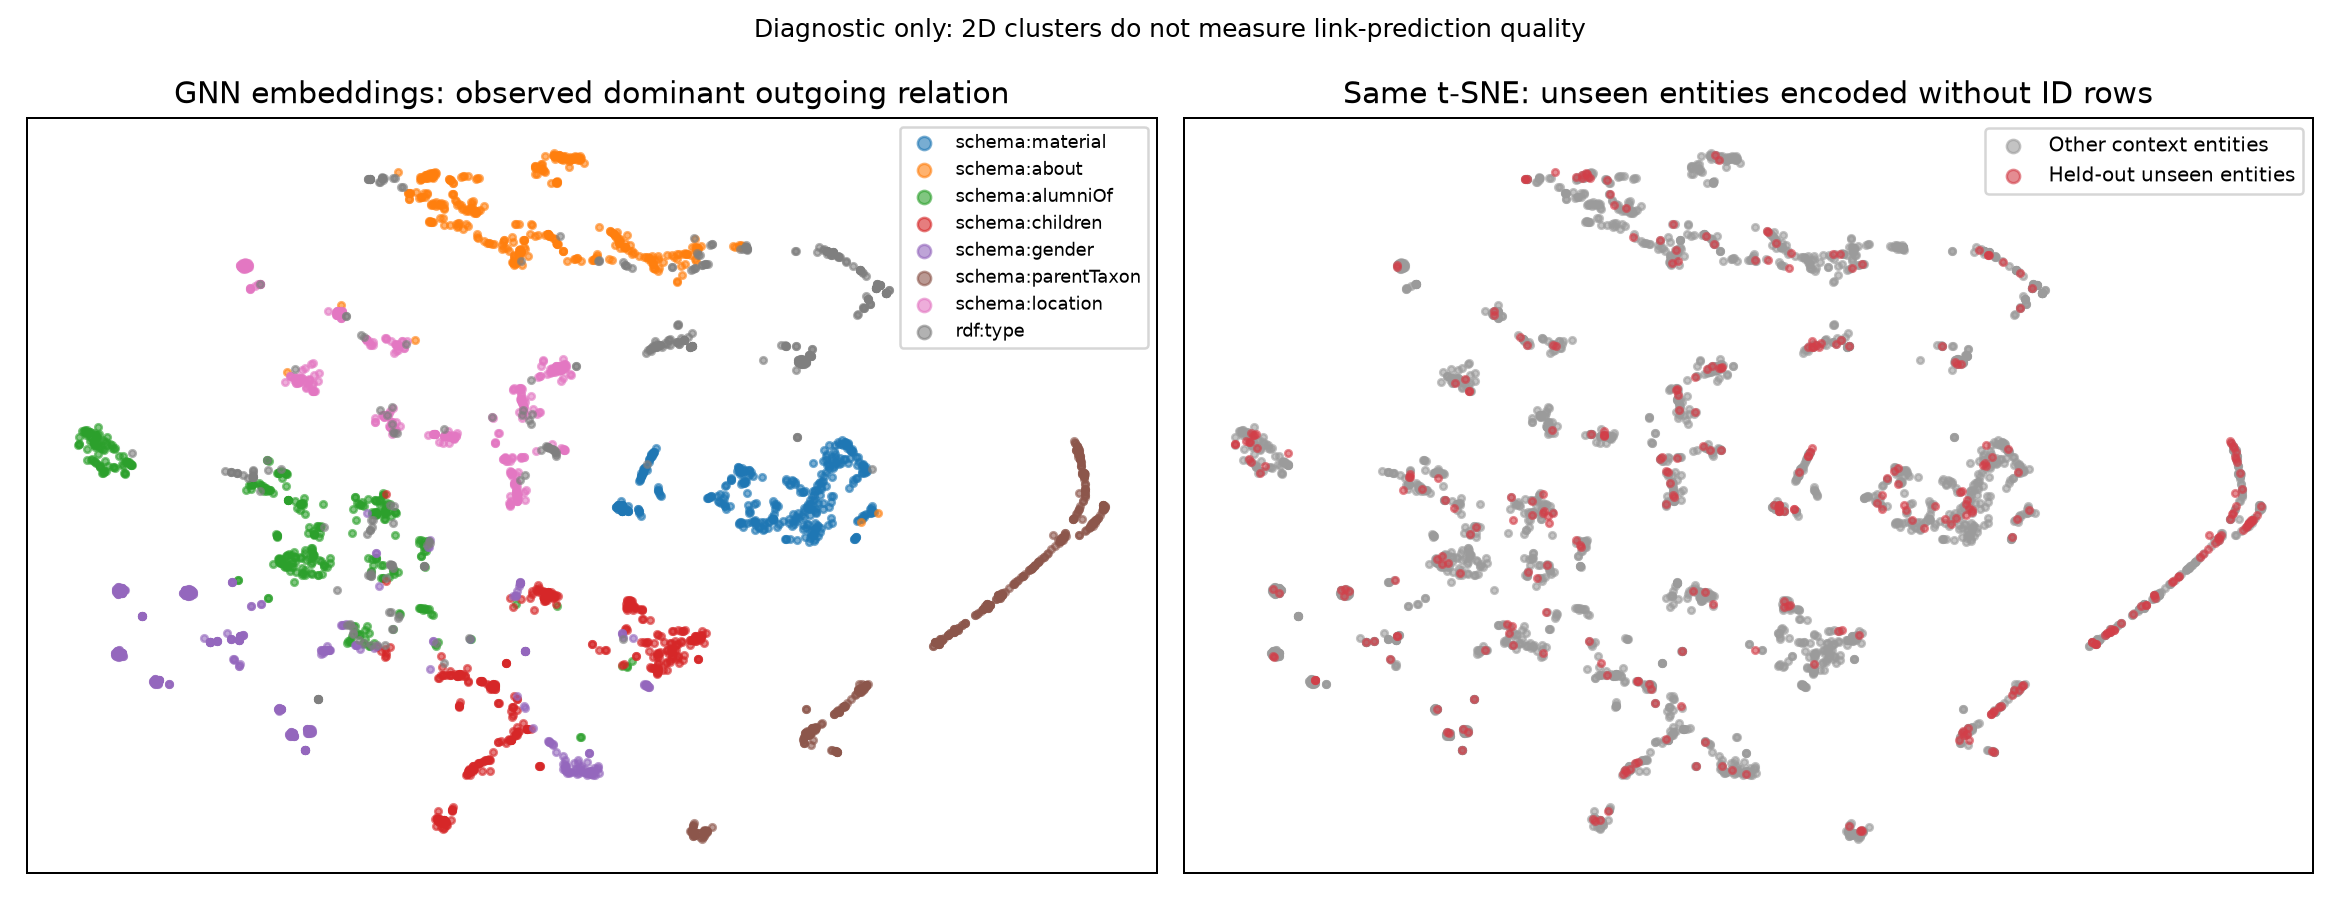

| Visualization diagnostic | Value |
|---|---|
| nodes | 3000 |
| unseen_nodes | 346 |
| seed | 13 |
| annotations | dominant relation in observed train+support context; diagnostic only |
| relation_1nn_agreement | 0.9706666666666667 |
| tsne_trustworthiness | 0.997864097838834 |
| mean_vector_standard_deviation | 0.050596509128808975 |

In [5]:
display(Image(filename=str(report / 'gnn_tsne.png')))
v = summary['visualization']
table(['Visualization diagnostic', 'Value'], list(v.items()))

Sampled contextual vectors include both train and unseen entities (see the
diagnostics table). Colors denote dominant relations in observed neighborhoods,
not held-out semantic classes.
t-SNE uses PCA initialization and a fixed seed. Relation 1-NN agreement and
trustworthiness measure this diagnostic only; they are **not semantic benchmark
accuracy**, and 2-D spacing must not be interpreted as calibrated similarity.

## Independent shallow embeddings t-SNE

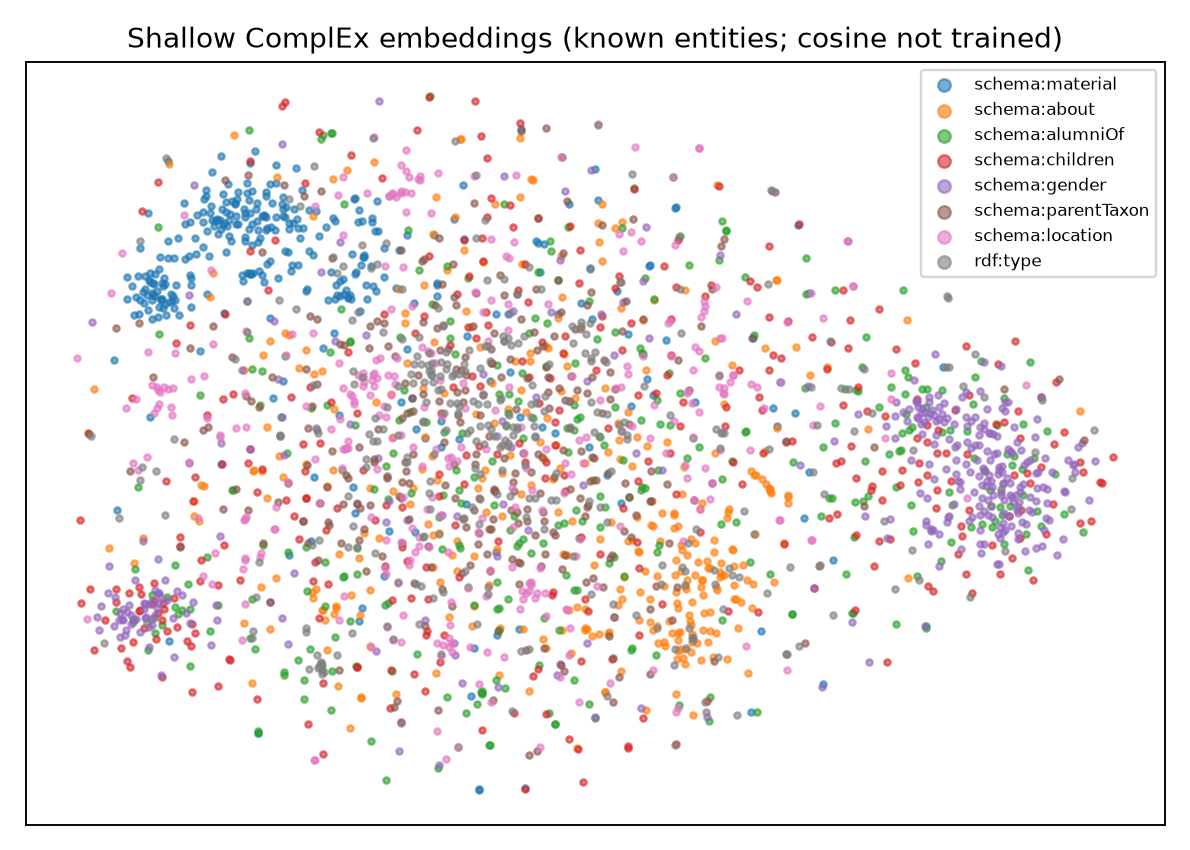

Final known-entity validation MRR: **0.633908**.

In [6]:
display(Image(filename=str(report / 'shallow_tsne.png')))
display(Markdown('Final known-entity validation MRR: **' +
                 f"{results['shallow_final_known_valid']['mrr']:.6f}" + '**.'))

## Complete all-node GNN cache and separate evaluation

In [7]:
cache = json.loads((report / 'cache_metadata.json').read_text())
cached_results = json.loads((report / 'cached_link_prediction.json').read_text())
table(['Cache property', 'Value'], [
    ['Shape', cache['matrix']['shape']], ['Dtype', cache['matrix']['dtype']],
    ['Complete', cache['complete']], ['All values finite', cache['matrix']['all_finite']],
    ['Matrix bytes', cache['matrix']['file_bytes']]])
table(['Candidates', 'MRR', 'Hits@1', 'Hits@10', 'Mean candidates', 'Frequency MRR'], [
    [policy, f"{r['mrr']:.6f}", f"{r['hits1']:.4f}", f"{r['hits10']:.4f}",
     f"{r['mean_candidates']:.3f}", f"{r['frequency_mrr']:.6f}"]
    for policy, r in cached_results.items()])

| Cache property | Value |
|---|---|
| Shape | [49281921, 200] |
| Dtype | float16 |
| Complete | True |
| All values finite | True |
| Matrix bytes | 19712768528 |

| Candidates | MRR | Hits@1 | Hits@10 | Mean candidates | Frequency MRR |
|---|---|---|---|---|---|
| uniform | 0.977372 | 0.9660 | 0.9980 | 51.000 | 0.967879 |
| relation-range | 0.887115 | 0.8270 | 0.9845 | 49.528 | 0.779899 |
| degree-matched | 0.572603 | 0.4225 | 0.8895 | 30.712 | 0.311573 |

Every mapped node has a 200-dimensional float16 vector. Before caching,
all held-out queries and same-relation reverses were globally scrubbed from
context and degree features. Static batched contexts differ from per-query
contexts; candidate pools/frequency controls also reflect the scrubbed graph.
These are separate measurements, not exact checkpoint-ranking reproduction.

The degree-matched diagnostic controls incoming-predicate degree with zero and
logarithmic nonzero bins. Its lower MRR reveals the difficulty hidden by easy
global negatives. Some bins have few candidates (30.7 mean versus 51 uniform),
so compare against its own controls, not directly against the other policies.
Frequency here is simply observed incoming-predicate count, with expected ties.


## Reusable artifacts and reproduction

- [Complete report and raw rankings](../experiments/inductive_full_entity2/README.md)
- [Source manifest and SHA256](../experiments/inductive_full_manifest.json)
- [Standalone GNN SavedModel](../experiments/inductive_full_entity2/gnn_saved_model/):
  about 1.3 MB; excludes entity-ID tables; exposes `encode`, `predict_graph`,
  and `score_embeddings`.
- [Method, training and CLI commands](../docs/09-inductive-autoencoder.md)
- [Tiny mixed-negative control](../experiments/inductive_tiny_mixed_10k/README.md)
- [Original range-only calibration failure](../experiments/inductive_tiny_10k/README.md)

Large optimizer checkpoints, shallow tables and the all-node float16 cache stay
under ignored `data/yago45_full/`. The cache has a separate evaluation because
batched static contexts and float16 vectors differ from per-query inference.
New entities require an observed neighborhood, not a trained entity-ID row.

Rebuild this executed notebook from `yago45-kge`:
```bash
.venv/bin/python -m pip install nbformat nbclient ipykernel
.venv/bin/python scripts/build_inductive_notebook.py --report experiments/inductive_full_entity2
```
